# Question 2: Vision in the Real World – Indian Currency Classification

**Estimated Time:** 8 Hours  
**Total:** 75 Points  
**Objective:** Apply CNNs to a culturally relevant, noisy dataset. Learn to reason about spatial dimensions, design parameter-efficient architectures, and interpret model decisions.

**Dataset:** “Indian Currency Notes” (denominations INR 10 – INR 2000). Create your own dataset, upload it to Google Drive, and share the link in submission. Resize all images to **128×128**.

> If unavailable, you may substitute **Oxford Flowers-102** (via `torchvision`) and mention it clearly in your submission.

## Part A: Theoretical Foundations [25 Points]

### 2A.1 Spatial Dimension Calculation [5 pts]
The output spatial dimension for a convolutional layer is:

$$
O = \left\lfloor \frac{I - K + 2P}{S} \right\rfloor + 1
$$

**(a)** Calculate output volume (**channels × height × width**) when a $3\times128\times128$ image passes through Conv2D with 32 filters, kernel $3\times3$, stride 2, padding 1.  
**(b)** Pass that output through another Conv2D with 64 filters, kernel $3\times3$, stride 1, padding 1. Give resulting volume.

(a) For the first Conv2D layer:
- Input dimensions: \( I = 128 \) (height and width), \( C_{in} = 3 \) (channels)
- Kernel size: \( K = 3 \times 3 \)
- Stride: \( S = 2 \)
- Padding: \( P = 1 \)
Calculating output height and width:
$$O = \left\lfloor \frac{128 - 3 + 2 \cdot 1}{2} \right\rfloor + 1 = \left\lfloor \frac{128 - 3 + 2}{2} \right\rfloor + 1 = \left\lfloor \frac{127}{2} \right\rfloor + 1 = 63 + 1 = 64$$
Output channels: \( C_{out} = 32 \)
Output volume: \( 32 \times 64 \times 64 \) 

(b) For the second Conv2D layer:
- Input dimensions: \( I = 64 \) (height and width), \( C_{in} = 32 \) (channels)
- Kernel size: \( K = 3 \times 3 \)
- Stride: \( S = 1 \)
- Padding: \( P = 1 \)
Calculating output height and width:
$$O = \left\lfloor \frac{64 - 3 + 2 \cdot 1}{1} \right\rfloor + 1 = \left\lfloor \frac{64 - 3 + 2}{1} \right\rfloor + 1 = \left\lfloor \frac{63}{1} \right\rfloor + 1 = 63 + 1 = 64$$
Output channels: \( C_{out} = 64 \)
Output volume: \( 64 \times 64 \times 64 \)

### 2A.2 Receptive Field [5 pts]

**(a)** Define receptive field of a convolutional neuron. Why should it cover a large part of the input image?  

**(b)** Compute receptive field at output of two stacked \(3\times3\) convolutions (stride 1, no pooling). Compare with one \(5\times5\) convolution and state which uses fewer parameters.

(a)
Receptive Field (RF) is defined as the size of the region in the input that produces the feature. Basically, it is a measure of association of an output feature (of any layer) to the input region (patch). a small receptive field may not be able to recognize large objects. large receptive fields are necessary for high-level recognition tasks. 

(b)
$$RF_l = RF_{l-1} + (k_l - 1) \times \prod_{i=1}^{l-1} s_i$$
where $k_l$ is the kernel size and $s_i$ is the stride at layer $i$. initial receptive field $RF_0 = 1$.
For two stacked \(3\times3\) convolutions:
- After first convolution:
$$RF_1 = RF_0 + (3 - 1) \times 1 = 1 + 2 = 3$$
- After second convolution:
$$RF_2 = RF_1 + (3 - 1) \times 1 = 3 + 2 = 5$$
So, the receptive field after two stacked \(3\times3\) convolutions is 5.


For one \(5\times5\) convolution:
$$RF = RF_0 + (5 - 1) \times 1 = 1 + 4 = 5$$
So, the receptive field for one \(5 \times 5\) convolution is 5.

### 2A.3 Parameter Efficiency [8 pts]

**(a)** Compute learnable parameters (weights + biases) for standard Conv2D mapping 32 input channels to 64 output channels with \(3\times3\) kernel.  

**(b)** Compute parameters for depthwise separable version: \(3 \times 3\) depthwise conv + \(1\times1\) pointwise conv (include biases).  

**(c)** Compute compression ratio and explain why MobileNet-style architectures use this factorization heavily.

## (a) Standard Conv2D


$$\text{weights} = 64 \times 32 \times 3 \times 3 = 18{,}432$$
$$\text{biases} = 64$$
$$\boxed{\text{total} = 18{,}496}$$

---

## (b) Depthwise Separable

**Depthwise conv** — one 3×3 filter per input channel, no cross-channel mixing:

$$\text{weights} = 32 \times 3 \times 3 = 288, \quad \text{biases} = 32$$

**Pointwise conv** — 1×1 conv combining all 32 channels into 64 outputs:

$$\text{weights} = 64 \times 32 \times 1 \times 1 = 2{,}048, \quad \text{biases} = 64$$

$$\boxed{\text{total} = 288 + 32 + 2{,}048 + 64 = 2{,}432}$$

---

## (c) Compression ratio

$$\text{ratio} = \frac{18{,}496}{2{,}432} \approx 7.6\times \text{ fewer parameters}$$

Depthwise separable factorizes them into two cheap sequential steps: spatial filtering costs only Cin×K2C_{in} \times K^2
Cin​×K2, then channel mixing costs Cin×CoutC_{in} \times C_{out}
Cin​×Cout​. The savings are multiplicative, so they compound across every layer in the network — making the total model ~8–9× smaller and faster,  which is needed to run inference on a mobile CPU in real time.



### 2A.4 BatchNorm vs. LayerNorm – Choosing the Right Normalization [7 pts]

**(a) BatchNorm axis (2 pts).** For feature map shape \((B,C,H,W)\), over which axes are mean/variance computed in BatchNorm?  

**(b) Small-batch failure mode (2 pts).** With batch size 2, why are BatchNorm statistics unreliable? Name one robust alternative (other than LayerNorm).
  
**(c) Why not BatchNorm in Transformers? (3 pts).** Explain why batch-level sequence statistics are problematic with padded variable-length sequences and why LayerNorm is preferred.

**(a)** BatchNorm computes mean and variance over the axes corresponding to the batch and spatial dimensions, i.e., over axes 0 (batch), 2 (height), and 3 (width). The normalization is done per channel, so the statistics are computed for each channel independently.

**(b)** With a batch size of 2, the mean and variance estimates for BatchNorm are highly unreliable because they are based on only two samples. This can lead to noisy updates and poor convergence during training. One robust alternative is **Group Normalization**, which divides channels into groups and computes statistics within each group, making it less sensitive to batch size.

**(c)** In Transformers, input sequences often have variable lengths and are padded to a common length for batch processing. BatchNorm relies on batch-level statistics, which can be skewed by the presence of padding tokens that do not represent meaningful data. This can lead to incorrect normalization and hinder model performance. LayerNorm, on the other hand, normalizes across the feature dimension for each individual token, making it unaffected by padding and thus more suitable for sequence data in Transformers.

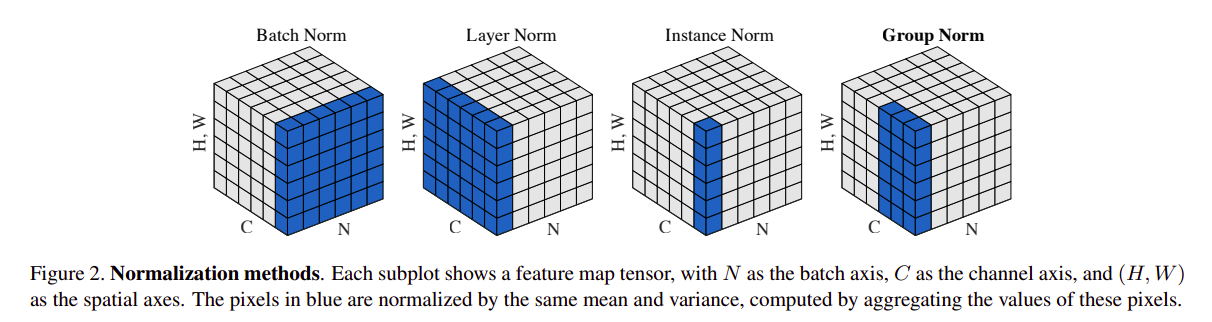

## Part B: Practical Implementation [50 Points]

### 2B.1 Baseline CNN [10 pts]
Design 4 conv blocks, each: `Conv2D → BatchNorm → ReLU → MaxPool(2)`.
Then use `Global Average Pooling → Linear`.
Train for 15 epochs and report training loss + test accuracy.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from PIL import Image

torch.manual_seed(42)

In [2]:
import warnings
warnings.filterwarnings('ignore')
#becuase of version some warning are making note book very untidy so adding this

In [3]:
train_dataset = datasets.ImageFolder(root='dataset/train-dataset', transform=transforms.Compose([transforms.ToTensor(), transforms.Resize((128,128))]))
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=8, pin_memory=True)
test_dataset = datasets.ImageFolder(root='dataset/test-dataset', transform=transforms.Compose([transforms.ToTensor(), transforms.Resize((128,128))]))
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=8, pin_memory=True)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [5]:
len(test_dataset), len(train_dataset)

(203, 3707)

In [6]:
train_dataset[0]

(tensor([[[0.9294, 0.9294, 0.9302,  ..., 0.9333, 0.9296, 0.9272],
          [0.9494, 0.9484, 0.9415,  ..., 0.9389, 0.9407, 0.9447],
          [0.9497, 0.9486, 0.9429,  ..., 0.9423, 0.9413, 0.9408],
          ...,
          [0.9505, 0.9442, 0.9416,  ..., 0.9511, 0.9589, 0.9601],
          [0.9457, 0.9418, 0.9388,  ..., 0.9491, 0.9529, 0.9513],
          [0.9440, 0.9515, 0.9450,  ..., 0.9479, 0.9497, 0.9531]],
 
         [[0.9098, 0.9098, 0.9106,  ..., 0.9110, 0.9100, 0.9076],
          [0.9298, 0.9288, 0.9219,  ..., 0.9167, 0.9211, 0.9251],
          [0.9301, 0.9290, 0.9233,  ..., 0.9203, 0.9217, 0.9212],
          ...,
          [0.9309, 0.9246, 0.9220,  ..., 0.9300, 0.9393, 0.9405],
          [0.9261, 0.9222, 0.9192,  ..., 0.9283, 0.9333, 0.9317],
          [0.9243, 0.9318, 0.9254,  ..., 0.9302, 0.9301, 0.9335]],
 
         [[0.8981, 0.8981, 0.8988,  ..., 0.9002, 0.8983, 0.8959],
          [0.9180, 0.9171, 0.9101,  ..., 0.9059, 0.9094, 0.9133],
          [0.9183, 0.9172, 0.9115,  ...,

In [7]:
img, label = train_dataset[0]
print(f"Image shape: {img.size}, Label: {label}")

Image shape: <built-in method size of Tensor object at 0x73ccb21542d0>, Label: 0


In [8]:
train_dataset.classes

['1', '10', '100', '2', '20', '200', '2000', '5', '50', '500']

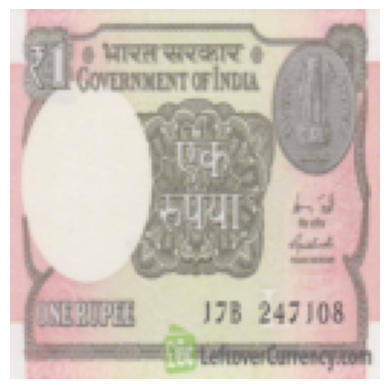

In [9]:
img = img.permute(1, 2, 0) # Convert from (C, H, W) to (H, W, C) for visualization
plt.imshow(img)
plt.axis('off')
plt.show()

In [10]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
    
    def forward(self, x):
        return self.block(x)
    

class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        
        self.layer1 = ConvBlock(3, 32)
        self.layer2 = ConvBlock(32, 64)
        self.layer3 = ConvBlock(64, 128)
        self.layer4 = ConvBlock(128, 256)
        
        self.gap = nn.AdaptiveAvgPool2d((1, 1)) 
        self.fc = nn.Linear(256, num_classes)
    
    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        
        x = self.gap(x)        # (B, 256, 1, 1)
        x = x.view(x.size(0), -1)  # flatten → (B, 256)
        x = self.fc(x)
        
        return x

In [11]:
len(train_dataset.classes)

10

In [12]:
model = CNN(num_classes=len(train_dataset.classes))
model.to(device)

CNN(
  (layer1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer3): ConvBlock(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (l

In [13]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 15 

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)  # Move to GPU if available
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

Epoch [1/15], Loss: 1.5865
Epoch [2/15], Loss: 1.2534
Epoch [3/15], Loss: 1.0036
Epoch [4/15], Loss: 0.8298
Epoch [5/15], Loss: 0.7098
Epoch [6/15], Loss: 0.5874
Epoch [7/15], Loss: 0.4935
Epoch [8/15], Loss: 0.4038
Epoch [9/15], Loss: 0.3737
Epoch [10/15], Loss: 0.3286
Epoch [11/15], Loss: 0.2998
Epoch [12/15], Loss: 0.2686
Epoch [13/15], Loss: 0.2293
Epoch [14/15], Loss: 0.1938
Epoch [15/15], Loss: 0.1914


In [14]:
def evaluate(model, test_dataset):
    correct = 0
    total = 0
    labels = []
    predicted = []
    model.eval()
    for img, label in test_dataset:
        img = img.unsqueeze(0).to(device)  
        output = model(img)
        predicted_label = torch.argmax(output, dim=1).item()
        labels.append(label)
        predicted.append(predicted_label)
        if predicted_label == label:
            correct += 1
        total += 1

        # print(f"True Label: {label}, Predicted Label: {predicted_label}")

    print(f"Accuracy: {correct/total*100:.2f}%")
    return labels, predicted
labels, predicted = evaluate(model, test_dataset)
print(labels)
print(predicted)

Accuracy: 36.45%
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 8, 8, 8, 8, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9]
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 9, 9, 1, 1, 5, 5, 5, 5, 1, 1, 1, 5, 5, 1, 1, 1, 1, 1, 9, 9, 9, 9, 9, 1, 1, 1, 1, 1, 1, 1, 6, 2, 1, 1, 2, 2, 2, 2, 2, 1, 6, 2, 6, 2, 1, 6, 1, 2, 2, 1, 6, 6, 2, 8, 6, 6, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 5, 4, 1, 1, 1, 1, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 1, 9, 1, 9, 9, 4, 9, 9, 9, 1, 1, 1, 1, 1, 1, 5, 1, 1, 1, 1, 1, 

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(labels,predicted))
print(confusion_matrix(labels,predicted))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        22
           1       0.16      0.61      0.25        28
           2       1.00      0.38      0.55        29
           3       0.00      0.00      0.00        13
           4       0.86      0.50      0.63        24
           5       0.22      0.08      0.12        24
           6       0.72      1.00      0.84        21
           7       1.00      0.40      0.57        10
           8       0.00      0.00      0.00         4
           9       0.28      0.25      0.26        28

    accuracy                           0.36       203
   macro avg       0.42      0.32      0.32       203
weighted avg       0.45      0.36      0.35       203

[[ 0 20  0  0  0  0  0  0  0  2]
 [ 0 17  0  0  0  6  0  0  0  5]
 [ 0  9 11  0  0  0  8  0  1  0]
 [ 0 10  0  0  2  1  0  0  0  0]
 [ 0  6  0  0 12  0  0  0  0  6]
 [ 0 22  0  0  0  2  0  0  0  0]
 [ 0  0  0  0  0  0 21  0  0  0]
 [ 0  0  0

In [16]:
model_focal = CNN(num_classes=len(train_dataset.classes))
model_focal.to(device)

CNN(
  (layer1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer3): ConvBlock(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (l

In [17]:
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        log_probs = F.log_softmax(inputs, dim=1)
        probs = torch.exp(log_probs)

        targets = targets.view(-1, 1)
        log_pt = log_probs.gather(1, targets).squeeze(1)
        pt = probs.gather(1, targets).squeeze(1)

        focal_loss = -self.alpha * (1 - pt) ** self.gamma * log_pt

        return focal_loss.mean()

In [18]:
loss_fn = FocalLoss()
optimizer = torch.optim.Adam(model_focal.parameters(), lr=0.001)
num_epochs = 15

for epoch in range(num_epochs):
    model_focal.train()
    total_loss = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)  # Move to GPU if available
        outputs = model_focal(images)
        loss = loss_fn(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")



Epoch [1/15], Loss: 1.1441
Epoch [2/15], Loss: 0.8085
Epoch [3/15], Loss: 0.6348
Epoch [4/15], Loss: 0.5446
Epoch [5/15], Loss: 0.4050
Epoch [6/15], Loss: 0.3899
Epoch [7/15], Loss: 0.3084
Epoch [8/15], Loss: 0.2612
Epoch [9/15], Loss: 0.2254
Epoch [10/15], Loss: 0.2147
Epoch [11/15], Loss: 0.1768
Epoch [12/15], Loss: 0.1718
Epoch [13/15], Loss: 0.1450
Epoch [14/15], Loss: 0.1322
Epoch [15/15], Loss: 0.1033


In [19]:
labels, predicted = evaluate(model_focal, test_dataset)
print(confusion_matrix(labels,predicted))

Accuracy: 47.29%
[[ 3  5  8  0  0  0  1  0  0  5]
 [ 0 19  0  2  0  0  1  0  1  5]
 [ 0  4 18  0  0  0  1  0  5  1]
 [ 0  0  0  5  8  0  0  0  0  0]
 [ 0  2  0  0 17  0  0  0  0  5]
 [ 0 23  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  0  0 21  0  0  0]
 [ 0  0  0  0  0  0  0  4  0  6]
 [ 0  0  0  0  0  0  0  0  4  0]
 [ 1 20  0  0  0  0  1  0  1  5]]


### 2B.2 Mobile-Friendly CNN [12 pts]
Replace the last two conv blocks with depthwise separable convolutions and train for 15 epochs.

**(a)** Print parameter count of both models using `sum(p.numel() for p in model.parameters())`.  
**(b)** Report test accuracy for both and check whether mobile-friendly model is comparable.  
**(c)** Compute actual compression ratio and compare with theoretical value from 2A.3.

In [20]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.depthwise = nn.Conv2d(
            in_channels, in_channels,
            kernel_size=3, padding=1,
            groups=in_channels,   
            bias=False           
        )

        self.pointwise = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=1,
            bias=False
        )

        self.bn  = nn.BatchNorm2d(out_channels)
        self.act = nn.ReLU()

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.bn(x)
        x = self.act(x)
        return x

In [21]:
class DSConvBlock(nn.Module):
    """Depthwise separable conv block — used for layer3 and layer4."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            DepthwiseSeparableConv(in_channels, out_channels),
            nn.MaxPool2d(kernel_size=2)
        )

    def forward(self, x):
        return self.block(x)

class MobileFriendlyCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.layer1 = ConvBlock(3,   32)   
        self.layer2 = ConvBlock(32,  64)   
        self.layer3 = DSConvBlock(64,  128) 
        self.layer4 = DSConvBlock(128, 256)  

        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc  = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x



In [22]:
model_mobile = MobileFriendlyCNN(num_classes=len(train_dataset.classes))

In [23]:
model_mobile.to(device)

MobileFriendlyCNN(
  (layer1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer3): DSConvBlock(
    (block): Sequential(
      (0): DepthwiseSeparableConv(
        (depthwise): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
        (pointwise): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=1e-05, m

In [24]:
loss_fn = FocalLoss()
optimizer = torch.optim.Adam(model_mobile.parameters(), lr=0.001)
num_epochs = 15 

for epoch in range(num_epochs):
    model_mobile.train()
    total_loss = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_mobile(images)
        loss = loss_fn(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")



Epoch [1/15], Loss: 1.1646
Epoch [2/15], Loss: 0.8085
Epoch [3/15], Loss: 0.6110
Epoch [4/15], Loss: 0.5025
Epoch [5/15], Loss: 0.3828
Epoch [6/15], Loss: 0.3265
Epoch [7/15], Loss: 0.2646
Epoch [8/15], Loss: 0.2252
Epoch [9/15], Loss: 0.1832
Epoch [10/15], Loss: 0.1572
Epoch [11/15], Loss: 0.1467
Epoch [12/15], Loss: 0.1359
Epoch [13/15], Loss: 0.1116
Epoch [14/15], Loss: 0.1035
Epoch [15/15], Loss: 0.1015


In [25]:
labels, predicted = evaluate(model_mobile, test_dataset)
print(confusion_matrix(labels,predicted))

Accuracy: 48.77%
[[ 0  9  9  0  0  0  0  0  0  4]
 [ 0 23  0  0  0  0  0  0  0  5]
 [ 0  3 22  0  1  0  3  0  0  0]
 [ 0  0  0  4  9  0  0  0  0  0]
 [ 0  4  0  0 13  0  0  0  0  7]
 [ 0 21  0  0  2  1  0  0  0  0]
 [ 0  0  0  0  0  0 21  0  0  0]
 [ 0  0  1  0  0  0  0  4  0  5]
 [ 0  0  0  0  0  0  0  0  4  0]
 [ 0 19  0  0  0  0  0  0  2  7]]


### 2B.3 Data Augmentation Study [10 pts]
Train mobile-friendly model with:
- `RandomRotation(±30°)`
- `ColorJitter(brightness=0.3, contrast=0.3)`
- `RandomHorizontalFlip(p=0.5)`
- `RandomAffine(degrees=0, translate=(0.1, 0.1))`

Report test accuracy change vs no augmentation.

**Thought:** Should augmentation be applied to test set? Justify in 2–3 sentences.

In [26]:
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import ConcatDataset

base_transform = T.Compose([
    T.ToTensor(),
    T.Resize((128, 128))
])

aug_transform = T.Compose([
    T.RandomRotation(30),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    T.ToTensor(),
    T.Resize((128, 128))
])

dataset_original = ImageFolder(root='dataset/train-dataset', transform=base_transform)
dataset_augmented = ImageFolder(root='dataset/train-dataset', transform=aug_transform)

final_dataset = ConcatDataset([dataset_original, dataset_augmented])
final_loader = DataLoader(final_dataset, batch_size=32, shuffle=True, num_workers=8, pin_memory=True)

In [27]:
model_data = MobileFriendlyCNN(num_classes=len(train_dataset.classes))
model_data.to(device)

MobileFriendlyCNN(
  (layer1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer3): DSConvBlock(
    (block): Sequential(
      (0): DepthwiseSeparableConv(
        (depthwise): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
        (pointwise): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=1e-05, m

In [28]:
loss_fn = FocalLoss()
optimizer = torch.optim.Adam(model_data.parameters(), lr=0.001)
num_epochs = 15 

for epoch in range(num_epochs):
    model_data.train()
    total_loss = 0
    
    for images, labels in final_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_data(images)
        loss = loss_fn(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(final_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

Epoch [1/15], Loss: 1.0582
Epoch [2/15], Loss: 0.6783
Epoch [3/15], Loss: 0.4974
Epoch [4/15], Loss: 0.3879
Epoch [5/15], Loss: 0.3186
Epoch [6/15], Loss: 0.2703
Epoch [7/15], Loss: 0.2198
Epoch [8/15], Loss: 0.2048
Epoch [9/15], Loss: 0.1994
Epoch [10/15], Loss: 0.1697
Epoch [11/15], Loss: 0.1477
Epoch [12/15], Loss: 0.1384
Epoch [13/15], Loss: 0.1407
Epoch [14/15], Loss: 0.1374
Epoch [15/15], Loss: 0.1203


In [29]:
labels, predicted = evaluate(model_data, test_dataset)
print(confusion_matrix(labels,predicted))

Accuracy: 56.65%
[[ 4 10  5  0  0  0  0  0  2  1]
 [ 0 24  2  0  0  0  0  0  0  2]
 [ 0  7 20  0  0  0  0  0  2  0]
 [ 0  0  0 11  2  0  0  0  0  0]
 [ 0  3  0  0 21  0  0  0  0  0]
 [ 0 22  0  0  0  2  0  0  0  0]
 [ 0  0  0  0  0  0 21  0  0  0]
 [ 0  0  5  0  0  0  0  5  0  0]
 [ 0  1  1  0  0  0  0  0  2  0]
 [ 0 23  0  0  0  0  0  0  0  5]]


### 2B.4 Interpretability with Grad-CAM [10 pts]
Using `pytorch-grad-cam`:

**(a)** Generate Grad-CAM heatmaps for final conv layer of baseline model.  
**(b)** Choose one correctly classified image from three denominations (e.g., INR 500, 200, 2000) and overlay heatmaps on originals.  
**(c)** Analyze in 3–4 sentences what model attends to (numeral, portrait, color, motif) and whether behavior is consistent.

In [30]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import cv2
import numpy as np

In [31]:
image, label = test_dataset[31]
input_tensor = image.unsqueeze(0) 

In [32]:
output = model_data(input_tensor.to(device))
predicted_label = torch.argmax(output, dim=1).item()
predicted_label

1

In [33]:
label

1

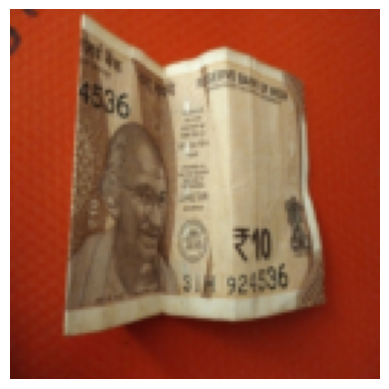

In [34]:
img = image.permute(1, 2, 0) # Convert from (C, H, W) to (H, W, C) for visualization
plt.imshow(img)
plt.axis('off')
plt.show()

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

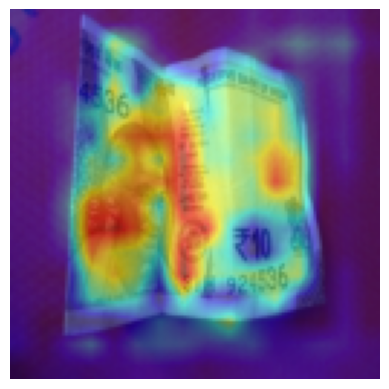

In [35]:
cam = GradCAM(model=model_mobile, target_layers=[model_mobile.layer4.block[0]])

grayscale_cam = cam(input_tensor=input_tensor)

image = input_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

visualization = show_cam_on_image(image, grayscale_cam[0], use_rgb=True)

plt.imshow(visualization)
plt.axis('off')

### 2B.5 Confusion Matrix Analysis [8 pts]

**(a)** Compute and display confusion matrix for best model on test set using `sklearn.metrics.confusion_matrix` and `seaborn.heatmap`.  
**(b)** Identify two most confused denomination pairs and hypothesize why (color, size, shared visual cues).  
**(c)** Propose one targeted strategy (beyond generic augmentation) to reduce this confusion.

In [45]:
labels, predicted = evaluate(model_data, test_dataset)
print(classification_report(labels,predicted, target_names=test_dataset.classes))
cm = confusion_matrix(labels,predicted)
print(cm)

Accuracy: 56.65%
              precision    recall  f1-score   support

           1       1.00      0.18      0.31        22
          10       0.27      0.86      0.41        28
         100       0.61      0.69      0.65        29
           2       1.00      0.85      0.92        13
          20       0.91      0.88      0.89        24
         200       1.00      0.08      0.15        24
        2000       1.00      1.00      1.00        21
           5       1.00      0.50      0.67        10
          50       0.33      0.50      0.40         4
         500       0.62      0.18      0.28        28

    accuracy                           0.57       203
   macro avg       0.77      0.57      0.57       203
weighted avg       0.77      0.57      0.55       203

[[ 4 10  5  0  0  0  0  0  2  1]
 [ 0 24  2  0  0  0  0  0  0  2]
 [ 0  7 20  0  0  0  0  0  2  0]
 [ 0  0  0 11  2  0  0  0  0  0]
 [ 0  3  0  0 21  0  0  0  0  0]
 [ 0 22  0  0  0  2  0  0  0  0]
 [ 0  0  0  0  0  0 21  0 

In [42]:
classes = train_dataset.classes

In [43]:
classes

['1', '10', '100', '2', '20', '200', '2000', '5', '50', '500']

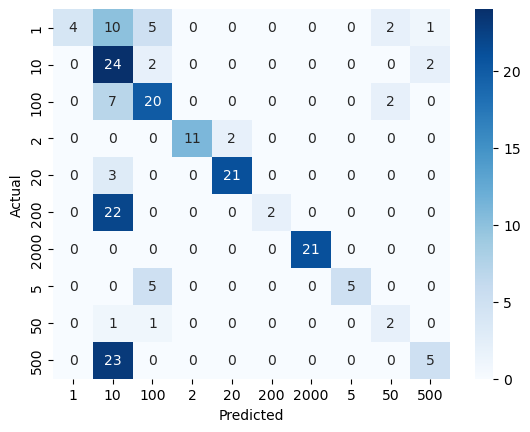

In [44]:
from seaborn import heatmap
import matplotlib.pyplot as plt

heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


The two most confused pairs are INR 500 vs INR 10 and INR 200 vs INR 10. I'm not sure why this is the case maybe due to the color of 10 notes similar to 200 in a lighter shade. or maybe it 10 notes classification is heavily dependent on mahatmagandhi and text, so all other classes are mostly classified to 10. 

We can do some kind of weighted loss that penalizes misclassification of 10 more heavily, or we can do some kind of hard example mining where we focus on training the model more on examples that are often confused with 10. Also the 10 notes which i had colllected contained many different shades becuase of old and new notes. if we take only the new notes which are more consistent in color and design, this will probably help the model to learn better features for 10 and reduce confusion with 200 and 500. But the main point is it should actually recognize the number 10 written on note, which is not the case.

Dataset link : https://drive.google.com/drive/folders/1qyDjIvpewuKtyWKMC87O9nC34upWADI8?usp=sharing 

Training dataset was taken from kaggle, and then additional images were scraped from web to augment the data. 

## AI Attribution
- It helped me a lot in formatting this to a proper format espically the markdown cells latex part.
- I used it in the implementation of depthwise convolution and composing transforms for data augmentation.
- It also taught me Grad cam which i was able to use later in the implementation.